# LODES flows: what the Phoenix commuting table contains

05.2 opened the New York flow table step by step and settled the unit: tracts, without the ones above 10 km2 of land. This notebook runs the same steps and the same code on the Phoenix table of 05.1, so the two areas can be compared: what the rows are, how large blocks and tracts are, how the workers spread over them, which tracts are large, and what is lost by dropping them.

| Step | What we do |
|---|---|
| 1. What we have | The rows of the flow table, the distribution of workers over pairs, straight-line distances, the strongest block pairs and county pairs, on a map |
| 2. Unit sizes | Land area of the blocks and tracts of the area from the Census boundary files, in square kilometres, with a map of the tracts |
| 3. Workers per unit | How the workers living and working in the area spread over blocks and over tracts, how many units are empty or nearly so, and how many pairs each level produces |
| 4. Large tracts | The tracts above a land-area threshold: how many, how many workers they hold, by county, and on an interactive map |
| 5. Dropping the large tracts | The area without the large tracts: the workers and flows lost by home, by workplace and by either end, the remaining tracts on a map, and the kept tracts and flows saved |
| 6. Large blocks | The same land-area thresholds applied to blocks, next to the tracts: how many units, how much land and how many workers lie above each |

In [1]:
import urllib.request
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

## Parameters

The flow table and the block list come from 05.1. Boundary files are the Census
Bureau's TIGER/Line blocks of 2023 (with the land and water area of each block) and the
cartographic tracts of 2023, one file per state of the area.

In [2]:
CITY = "Phoenix"
YEAR = 2023
STATES = {"04": "AZ"}   # states of the metropolitan area, by FIPS code
STRONGEST = 20                       # flows shown in the tables
BIG_TRACT_KM2 = 20
THRESHOLDS_KM2 = [2, 4, 10, 20]        # land-area thresholds compared for blocks and tracts                   # a tract above this land area counts as large

RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting") / CITY.lower().replace(" ", "-")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
FLOWS = RESULTS / f"lodes-metro-od-JT01-{YEAR}.parquet"
BLOCKS = RESULTS / f"lodes-metro-blocks-{YEAR}.parquet"

TIGER = Path("/scratch/project_2010423/data/tiger")
TIGER.mkdir(parents=True, exist_ok=True)
BLOCK_SHAPES_URL = "https://www2.census.gov/geo/tiger/TIGER2023/TABBLOCK20/tl_2023_{fips}_tabblock20.zip"
TRACT_SHAPES_URL = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_{fips}_tract_500k.zip"

## 1. What we have

One row is a pair of blocks, the home block and the work block, with the number of
workers whose primary job connects them. There are no persons, no trips, no departure
times and no modes: LODES says how many people live in block A and work in block B,
nothing more. Most pairs carry a single worker.

In [3]:
flows = pd.read_parquet(FLOWS)
blocks = pd.read_parquet(BLOCKS).set_index("tabblk2020")
print(f"{len(flows):,} block pairs, {flows['S000'].sum():,} workers, "
      f"{flows['h_geocode'].nunique():,} home blocks, {flows['w_geocode'].nunique():,} work blocks, "
      f"{len(blocks):,} blocks in the area")
print("\nworkers per pair:")
display(flows["S000"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame().T)
print(f"pairs with one worker: {(flows['S000'] == 1).mean():.1%} of pairs, {flows.loc[flows['S000'] == 1, 'S000'].sum() / flows['S000'].sum():.1%} of workers")
flows.head()

1,894,597 block pairs, 2,039,140 workers, 57,580 home blocks, 24,452 work blocks, 74,236 blocks in the area

workers per pair:


,count,mean,std,min,50%,90%,99%,max
S000,1894597.0,1.1,0.4,1.0,1.0,1.0,3.0,89.0


pairs with one worker: 94.4% of pairs, 87.7% of workers


,w_geocode,h_geocode,S000
0,040130101021045,040130101023023,1
1,040130101021045,040133192014001,1
2,040130101021045,040134205061009,1
3,040130101021045,040136133004008,1
4,040130101021045,040136152012022,1


Straight-line distance of each pair between the internal points of its two blocks, and
how many workers stay within the same block, tract or county. Block codes nest: the
first five digits are the county, the first eleven the tract.

In [4]:
def weighted_percentiles(values, weights, percentiles):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return [values[order][np.searchsorted(cumulative, p / 100)] for p in percentiles]


home = blocks.loc[flows["h_geocode"]]
work = blocks.loc[flows["w_geocode"]]
flows["km"] = np.hypot((work["blklondd"].to_numpy() - home["blklondd"].to_numpy()) * np.cos(np.radians(home["blklatdd"].to_numpy())) * 111.32,
                       (work["blklatdd"].to_numpy() - home["blklatdd"].to_numpy()) * 110.57)
flows["same_block"] = flows["h_geocode"] == flows["w_geocode"]
flows["same_tract"] = flows["h_geocode"].str[:11] == flows["w_geocode"].str[:11]
flows["same_county"] = flows["h_geocode"].str[:5] == flows["w_geocode"].str[:5]

percentiles = [10, 25, 50, 75, 90]
print("straight-line distance home to work, weighted by workers (km):")
display(pd.Series(weighted_percentiles(flows["km"].to_numpy(), flows["S000"].to_numpy(), percentiles), index=[f"p{p}" for p in percentiles]).round(1).to_frame("km").T)
print("share of workers whose home and work are in the same unit:")
pd.Series({unit: flows.loc[flows[f"same_{unit}"], "S000"].sum() / flows["S000"].sum() for unit in ["block", "tract", "county"]}).round(3).to_frame("share").T

straight-line distance home to work, weighted by workers (km):


,p10,p25,p50,p75,p90
km,4.8,10.2,19.0,31.2,46.1


share of workers whose home and work are in the same unit:


,block,tract,county
share,0.001,0.022,0.922


The strongest block pairs. A block pair with hundreds of workers is typically a large
housing estate or a residential tower and a large employer: a hospital, a campus, an
office tower.

In [5]:
strongest = flows.nlargest(STRONGEST, "S000").copy()
strongest["home"] = blocks.loc[strongest["h_geocode"], "ctyname"].to_numpy()
strongest["home_place"] = blocks.loc[strongest["h_geocode"], "stplcname"].to_numpy()
strongest["work"] = blocks.loc[strongest["w_geocode"], "ctyname"].to_numpy()
strongest["work_place"] = blocks.loc[strongest["w_geocode"], "stplcname"].to_numpy()
strongest[["h_geocode", "home_place", "home", "w_geocode", "work_place", "work", "S000", "km"]].rename(columns={"S000": "workers"}).round(1).reset_index(drop=True)

,h_geocode,home_place,home,w_geocode,work_place,work,workers,km
0,040131072011012,"Phoenix city, AZ","Maricopa County, AZ",040131072011010,"Phoenix city, AZ","Maricopa County, AZ",89,0.7
1,040136123012021,"Phoenix city, AZ","Maricopa County, AZ",040136113002002,"Phoenix city, AZ","Maricopa County, AZ",67,10.3
2,040131072011008,"Phoenix city, AZ","Maricopa County, AZ",040131072011010,"Phoenix city, AZ","Maricopa County, AZ",64,0.2
3,040131072011012,"Phoenix city, AZ","Maricopa County, AZ",040131072011004,"Phoenix city, AZ","Maricopa County, AZ",61,1.0
4,040136164003005,"Phoenix city, AZ","Maricopa County, AZ",040136165002000,"Phoenix city, AZ","Maricopa County, AZ",53,1.0
5,040131072011008,"Phoenix city, AZ","Maricopa County, AZ",040131072011004,"Phoenix city, AZ","Maricopa County, AZ",50,0.4
6,040136152012019,"Phoenix city, AZ","Maricopa County, AZ",040132168581001,"Scottsdale city, AZ","Maricopa County, AZ",50,14.3
7,040139413004048,None,"Maricopa County, AZ",040139413001074,None,"Maricopa County, AZ",50,3.7
8,040133190021000,"Tempe city, AZ","Maricopa County, AZ",040133190011002,"Tempe city, AZ","Maricopa County, AZ",47,0.8
9,040136116002000,"Phoenix city, AZ","Maricopa County, AZ",040136113002002,"Phoenix city, AZ","Maricopa County, AZ",46,7.6


The same flows summed to counties: where the commuting of the area goes. The table
lists the strongest county pairs, within-county pairs included, and the map draws the
between-county ones as lines between the mean position of each county's blocks.

In [6]:
flows["home_county"] = blocks.loc[flows["h_geocode"], "ctyname"].to_numpy()
flows["work_county"] = blocks.loc[flows["w_geocode"], "ctyname"].to_numpy()
county_flows = flows.groupby(["home_county", "work_county"])["S000"].sum().sort_values(ascending=False)
county_flows = (county_flows / flows["S000"].sum()).rename("share of workers").to_frame()
county_flows["workers"] = flows.groupby(["home_county", "work_county"])["S000"].sum()
print(f"{len(county_flows):,} county pairs; the {STRONGEST} strongest carry {county_flows['share of workers'].head(STRONGEST).sum():.1%} of the workers")
county_flows.head(STRONGEST).round(3)

4 county pairs; the 20 strongest carry 100.0% of the workers


share of workers  workers
home_county         work_county                                   
Maricopa County, AZ Maricopa County, AZ             0.904  1842888
Pinal County, AZ    Maricopa County, AZ             0.067   135955
                    Pinal County, AZ                0.018    37445
Maricopa County, AZ Pinal County, AZ                0.011    22852

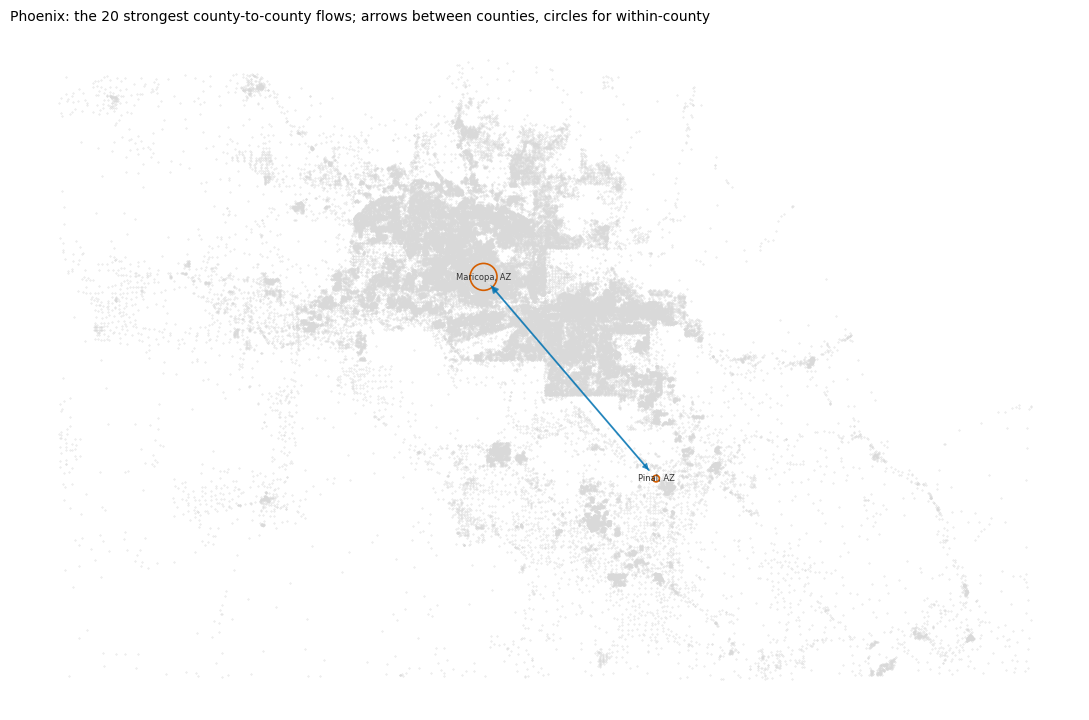

In [7]:
centres = blocks.groupby("ctyname")[["blklondd", "blklatdd"]].mean()
figure, axis = plt.subplots(figsize=(11, 9))
axis.scatter(blocks["blklondd"], blocks["blklatdd"], s=0.1, color="#d9d9d9")
largest = county_flows.head(STRONGEST)
for (home_county, work_county), row in largest.iterrows():
    a, b = centres.loc[home_county], centres.loc[work_county]
    width = 0.5 + 12 * row["workers"] / largest["workers"].max()
    if home_county == work_county:
        axis.scatter(a["blklondd"], a["blklatdd"], s=30 * width, facecolor="none", edgecolor="#D55E00", linewidth=1.2, zorder=3)
    else:
        axis.annotate("", xy=(b["blklondd"], b["blklatdd"]), xytext=(a["blklondd"], a["blklatdd"]),
                      arrowprops=dict(arrowstyle="-|>", color="#0072B2", lw=width, alpha=0.7, shrinkA=8, shrinkB=8))
for county, point in centres.iterrows():
    axis.text(point["blklondd"], point["blklatdd"], county.replace(" County", "").replace(", NY", "").replace(", NJ", ""), fontsize=6, ha="center", va="center", color="#333333")
axis.set_aspect(1 / np.cos(np.radians(blocks["blklatdd"].mean())))
axis.set_title(f"{CITY}: the {STRONGEST} strongest county-to-county flows; arrows between counties, circles for within-county", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()

## 2. Unit sizes

Land area of every block and tract of the area, from the TIGER/Line block file
(`ALAND20`, square metres) and the cartographic tract file (`ALAND`). Water is left
out, so a block on the shore is measured by its land. Blocks of the area are selected
from the block list of 05.1; tracts from the first eleven digits of the block codes.

In [8]:
block_shapes = []
tract_shapes = []
for fips, state in STATES.items():
    for url, store in [(BLOCK_SHAPES_URL, block_shapes), (TRACT_SHAPES_URL, tract_shapes)]:
        path = TIGER / url.format(fips=fips).rsplit("/", 1)[1]
        if not path.exists():
            urllib.request.urlretrieve(url.format(fips=fips), path)
        store.append(gpd.read_file(path))
        print(path.name, f"{path.stat().st_size / 1e6:.0f} MB, {len(store[-1]):,} features")
block_shapes = pd.concat(block_shapes, ignore_index=True)
tract_shapes = pd.concat(tract_shapes, ignore_index=True)

area_blocks = block_shapes.loc[block_shapes["GEOID20"].isin(blocks.index), ["GEOID20", "ALAND20", "AWATER20", "geometry"]].rename(columns={"GEOID20": "block"})
area_blocks["land_km2"] = area_blocks["ALAND20"] / 1e6
tracts_in_area = set(blocks.index.str[:11])
area_tracts = tract_shapes.loc[tract_shapes["GEOID"].isin(tracts_in_area), ["GEOID", "NAMELSADCO", "ALAND", "AWATER", "geometry"]].rename(columns={"GEOID": "tract"})
area_tracts["land_km2"] = area_tracts["ALAND"] / 1e6
print(f"{len(area_blocks):,} blocks and {len(area_tracts):,} tracts of the area matched to boundaries; "
      f"land {area_blocks['land_km2'].sum():,.0f} km2 by blocks, {area_tracts['land_km2'].sum():,.0f} km2 by tracts")

sizes = pd.DataFrame({
    "block": area_blocks["land_km2"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]),
    "tract": area_tracts["land_km2"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]),
}).T
print("land area per unit (km2):")
sizes.round(3)

tl_2023_04_tabblock20.zip 115 MB, 155,444 features


cb_2023_04_tract_500k.zip 1 MB, 1,765 features
74,236 blocks and 1,104 tracts of the area matched to boundaries; land 37,733 km2 by blocks, 37,733 km2 by tracts
land area per unit (km2):


,count,mean,std,min,10%,50%,90%,99%,max
block,74236.0,0.508,6.292,0.000,0.008,0.028,0.321,7.097,558.857
tract,1104.0,34.178,226.597,0.321,1.275,2.591,16.481,789.671,3455.325


Workers by home and by workplace per tract, and the tracts on three maps: land area,
workers living per square kilometre, and workers working per square kilometre. All on a
logarithmic colour scale, since the values span three orders of magnitude from
Manhattan to the fringe.

workers per tract:


,count,mean,std,min,10%,50%,90%,max
workers_home,1104.0,1847.0,815.0,59.0,840.0,1794.0,2827.0,5488.0
workers_work,1104.0,1847.0,3796.0,0.0,133.0,662.0,4211.0,43954.0


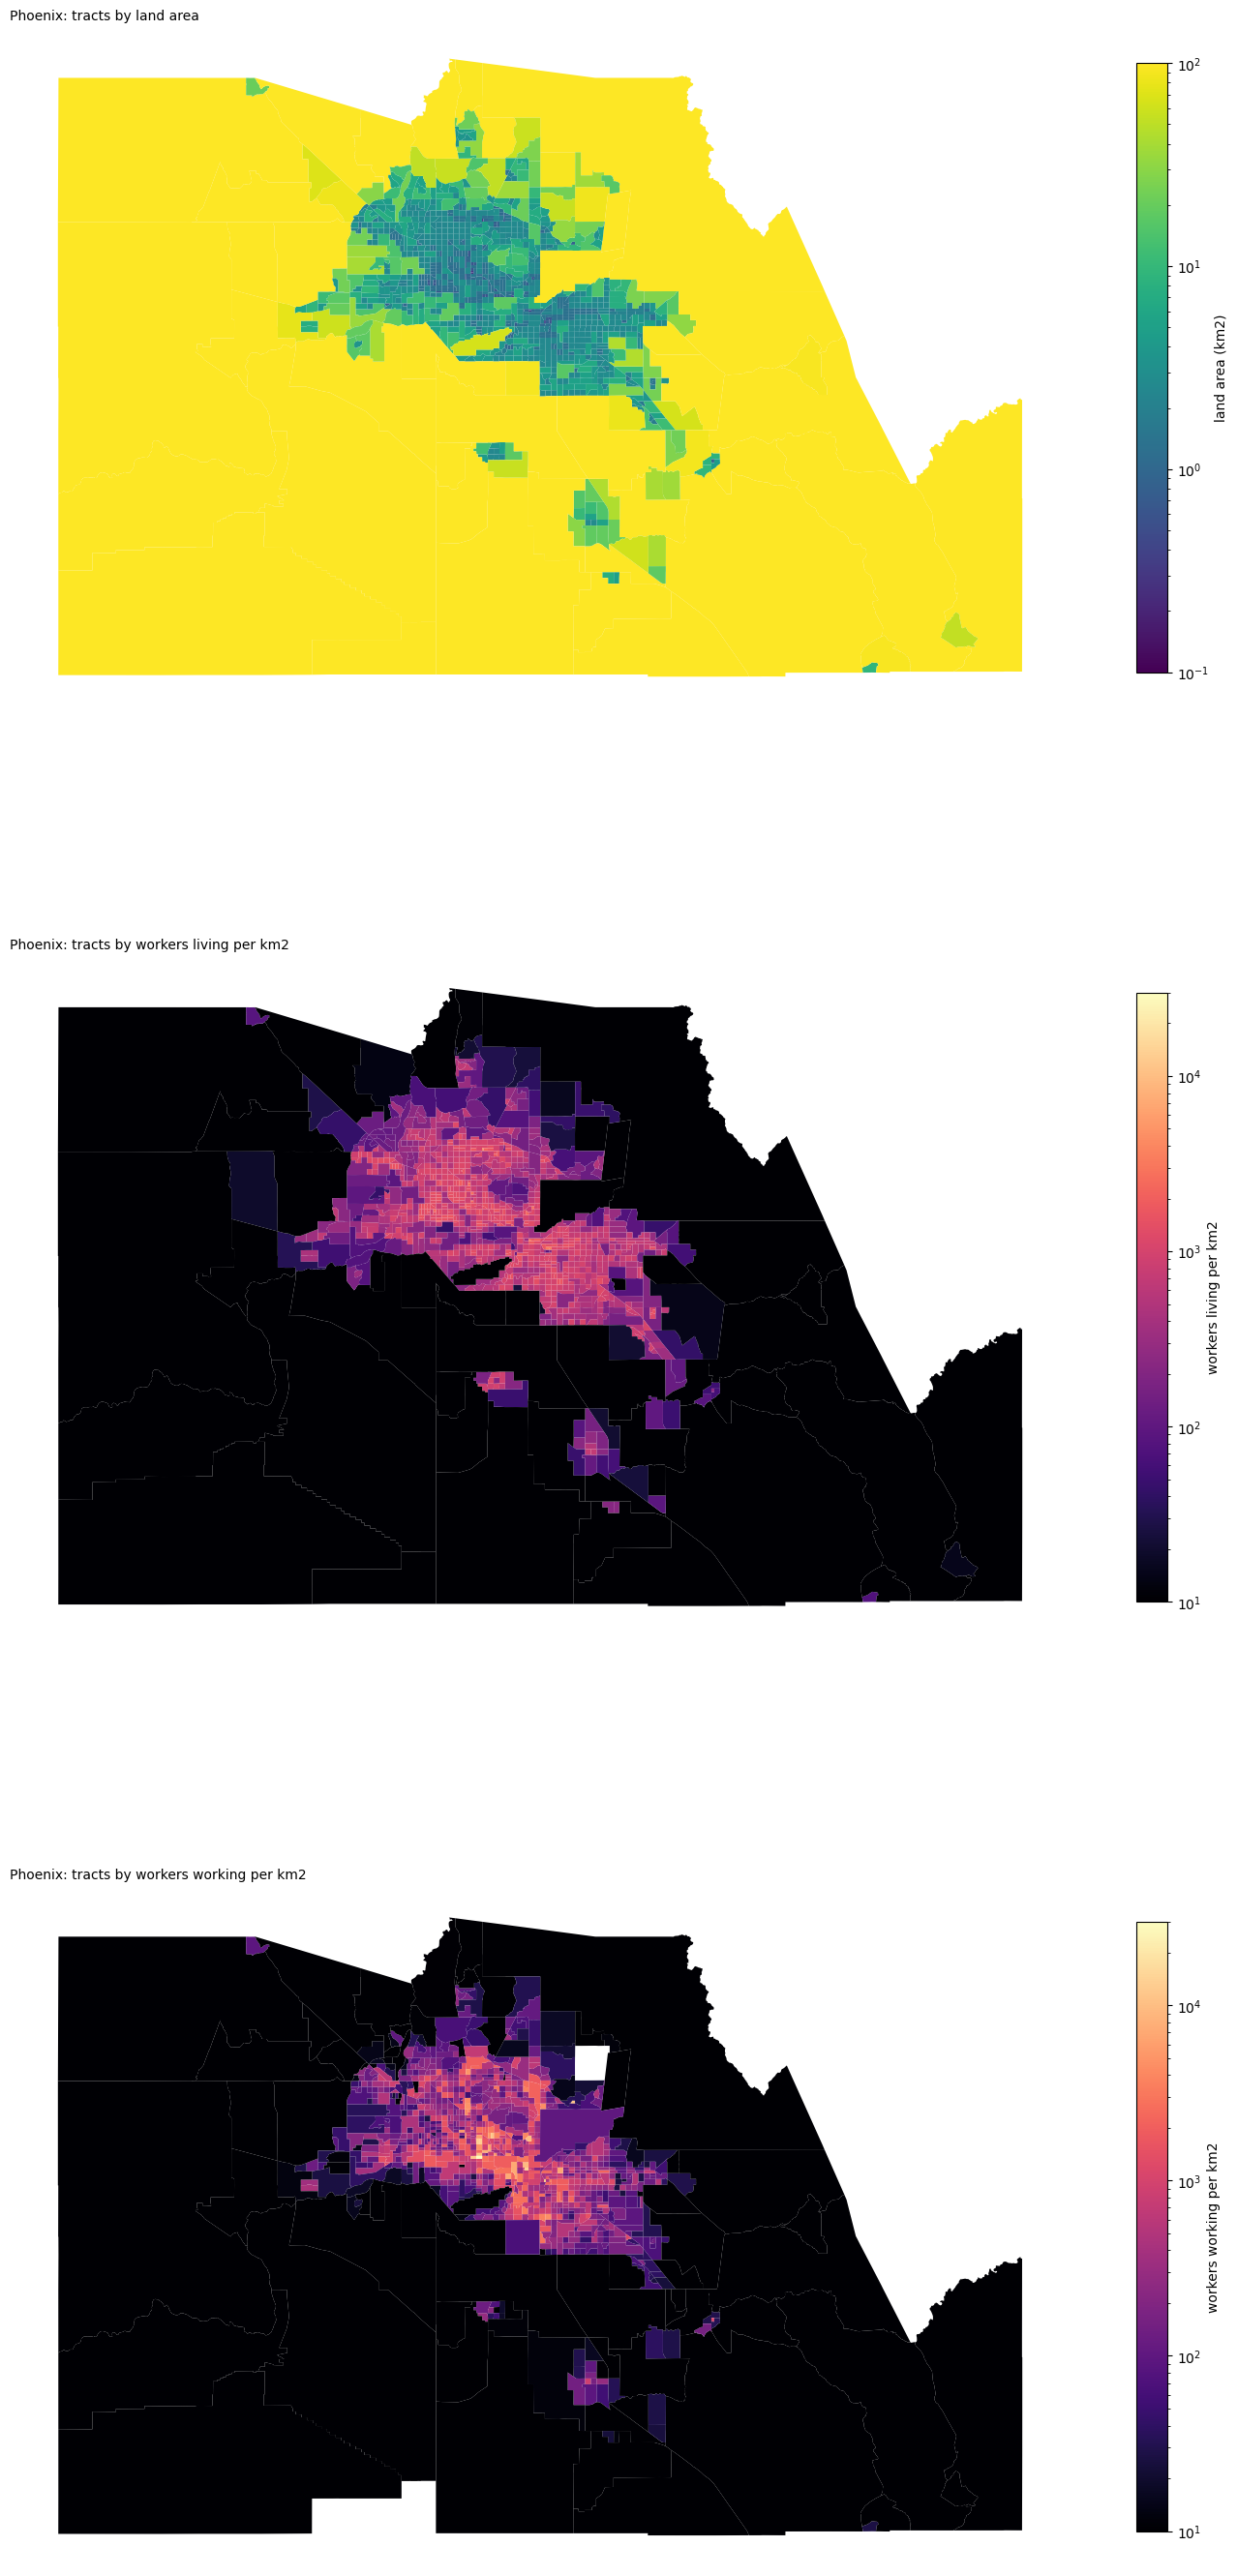

In [9]:
by_home = flows.assign(tract=flows["h_geocode"].str[:11]).groupby("tract")["S000"].sum().rename("workers_home")
by_work = flows.assign(tract=flows["w_geocode"].str[:11]).groupby("tract")["S000"].sum().rename("workers_work")
area_tracts = area_tracts.merge(by_home, left_on="tract", right_index=True, how="left").merge(by_work, left_on="tract", right_index=True, how="left")
area_tracts[["workers_home", "workers_work"]] = area_tracts[["workers_home", "workers_work"]].fillna(0)
area_tracts["home_per_km2"] = area_tracts["workers_home"] / area_tracts["land_km2"].replace(0, np.nan)
area_tracts["work_per_km2"] = area_tracts["workers_work"] / area_tracts["land_km2"].replace(0, np.nan)
area_tracts.to_parquet(RESULTS / f"tracts-{YEAR}.parquet", index=False)

print("workers per tract:")
display(area_tracts[["workers_home", "workers_work"]].describe(percentiles=[0.1, 0.5, 0.9]).round(0).T)

figure, axes = plt.subplots(nrows=3, figsize=(14, 30))
area_tracts.plot(column="land_km2", ax=axes[0], cmap="viridis", norm=LogNorm(vmin=0.1, vmax=100), edgecolor="none",
                 legend=True, legend_kwds={"shrink": 0.6, "label": "land area (km2)"})
axes[0].set_title(f"{CITY}: tracts by land area", loc="left", fontsize=10)
area_tracts.plot(column="home_per_km2", ax=axes[1], cmap="magma", norm=LogNorm(vmin=10, vmax=30000), edgecolor="none",
                 legend=True, legend_kwds={"shrink": 0.6, "label": "workers living per km2"}, missing_kwds={"color": "#ececea"})
axes[1].set_title(f"{CITY}: tracts by workers living per km2", loc="left", fontsize=10)
area_tracts.plot(column="work_per_km2", ax=axes[2], cmap="magma", norm=LogNorm(vmin=10, vmax=30000), edgecolor="none",
                 legend=True, legend_kwds={"shrink": 0.6, "label": "workers working per km2"}, missing_kwds={"color": "#ececea"})
axes[2].set_title(f"{CITY}: tracts by workers working per km2", loc="left", fontsize=10)
for axis in axes:
    axis.set_axis_off()
figure.tight_layout()

## 3. Workers per unit

The same workers counted by home block and by work block, then by home tract and by
work tract, over every unit of the area including the ones with no worker at all.
LODES counts workers with a primary job inside the area, so a block with none still has
residents: children, retired people, the unemployed and people working outside the
area. Blocks are protected by noise infusion in LODES, so small block counts are
individually unreliable by construction and only become accurate when summed over
larger units.

The last table counts the pairs at each level: how many origin-destination pairs a
routing would have to cover if the units were blocks or tracts.


In [10]:
units = {}
for level, digits in [("block", 15), ("tract", 11)]:
    index = pd.Index(sorted(set(blocks.index.str[:digits])), name=level)
    units[level] = pd.DataFrame({
        "workers_home": flows.groupby(flows["h_geocode"].str[:digits])["S000"].sum().reindex(index, fill_value=0),
        "workers_work": flows.groupby(flows["w_geocode"].str[:digits])["S000"].sum().reindex(index, fill_value=0),
    })

rows = {}
for level, table in units.items():
    for column in table.columns:
        values = table[column]
        rows[(level, column.replace("workers_", ""))] = pd.Series({
            "units": len(values),
            "share of units with none": (values == 0).mean(),
            "share of units under 10": (values < 10).mean(),
            "share of workers in units under 10": values[values < 10].sum() / values.sum(),
            "mean": values.mean(),
            "p10": values.quantile(0.1),
            "p50": values.quantile(0.5),
            "p90": values.quantile(0.9),
            "max": values.max(),
        })
summary = pd.DataFrame(rows).T
summary.index.names = ["unit", "counted by"]
print("workers per unit, over all units of the area:")
display(summary.round(3))

tract_pairs = flows.groupby([flows["h_geocode"].str[:11], flows["w_geocode"].str[:11]])["S000"].sum()
pairs = pd.DataFrame({
    "pairs": [len(flows), len(tract_pairs)],
    "share of pairs with one worker": [(flows["S000"] == 1).mean(), (tract_pairs == 1).mean()],
    "share of workers on single-worker pairs": [flows.loc[flows["S000"] == 1, "S000"].sum() / flows["S000"].sum(), tract_pairs[tract_pairs == 1].sum() / tract_pairs.sum()],
    "workers per pair, p50": [flows["S000"].median(), tract_pairs.median()],
    "workers per pair, p90": [flows["S000"].quantile(0.9), tract_pairs.quantile(0.9)],
    "workers per pair, max": [flows["S000"].max(), tract_pairs.max()],
}, index=pd.Index(["block", "tract"], name="unit"))
print("origin-destination pairs at each level:")
pairs.round(3)


workers per unit, over all units of the area:


units  share of units with none  share of units under 10  \
unit  counted by                                                               
block home        74236.0                     0.224                    0.382   
      work        74236.0                     0.671                    0.868   
tract home         1104.0                     0.000                    0.000   
      work         1104.0                     0.002                    0.007   

                  share of workers in units under 10      mean    p10     p50  \
unit  counted by                                                                
block home                                     0.029    27.468    0.0    16.0   
      work                                     0.024    27.468    0.0     0.0   
tract home                                     0.000  1847.047  840.5  1793.5   
      work                                     0.000  1847.047  133.3   662.0   

                     p90      max  
unit  counted by                   
block home          59.0   1001.0  
      work          18.0  14479.0  
tract home        2827.0   5488.0  
      work        4211.2  43954.0

origin-destination pairs at each level:


,pairs,share of pairs with one worker,share of workers on single-worker pairs,"workers per pair, p50","workers per pair, p90","workers per pair, max"
unit,,,,,,
block,1894597,0.944,0.877,1.0,1.0,89
tract,449962,0.413,0.091,2.0,10.0,1102


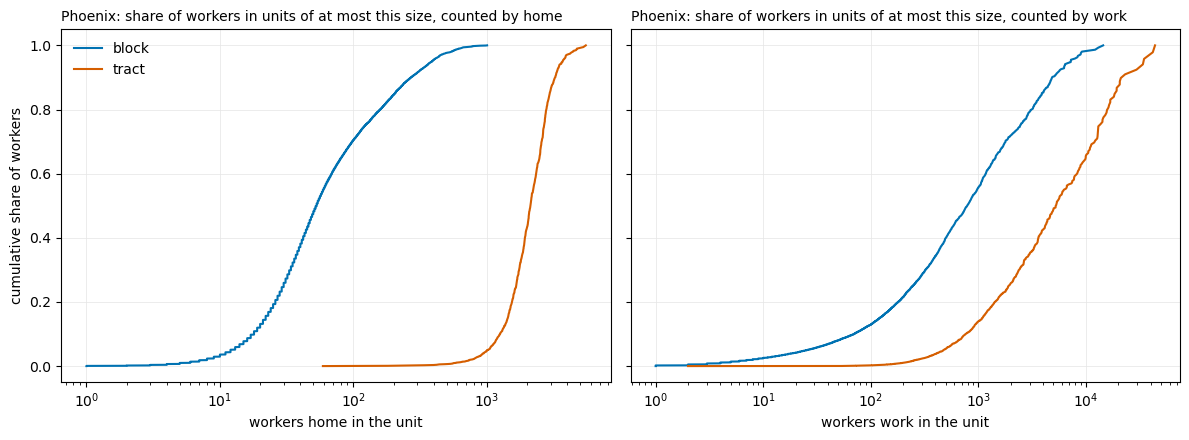

In [11]:
colours = {"block": "#0072B2", "tract": "#D55E00"}
figure, axes = plt.subplots(ncols=2, figsize=(12, 4.5), sharey=True)
for axis, column in zip(axes, ["workers_home", "workers_work"]):
    for level, table in units.items():
        values = np.sort(table[column].to_numpy())
        values = values[values > 0]
        axis.plot(values, np.cumsum(values) / values.sum(), color=colours[level], linewidth=1.5, label=level)
    axis.set_xscale("log")
    axis.set_xlabel(f"workers {column.split('_')[1]} in the unit")
    axis.grid(True, color="#e5e5e5", linewidth=0.5)
    axis.set_title(f"{CITY}: share of workers in units of at most this size, counted by {column.split('_')[1]}", loc="left", fontsize=10)
axes[0].set_ylabel("cumulative share of workers")
axes[0].legend(frameon=False)
figure.tight_layout()


## 4. Large tracts

Tracts are drawn to hold a few thousand residents, so they grow where people are few:
the median tract of the area is half a square kilometre, but the fringe has tracts of
tens of square kilometres, and a centroid there can misplace a home by kilometres. The
table counts the tracts with more than `BIG_TRACT_KM2` square kilometres of land by
county, with the share of the area's workers who live and work in them. The map draws
them filled by land area, the remaining tracts as thin outlines, with the figures of each
tract on hover; it is also saved as an HTML file next to the notebook.


In [12]:
area_tracts["large"] = area_tracts["land_km2"] > BIG_TRACT_KM2
large = area_tracts.loc[area_tracts["large"]]
print(f"{len(large):,} of {len(area_tracts):,} tracts ({len(large) / len(area_tracts):.1%}) have more than {BIG_TRACT_KM2} km2 of land; "
      f"they cover {large['land_km2'].sum() / area_tracts['land_km2'].sum():.1%} of the land, "
      f"hold {large['workers_home'].sum() / area_tracts['workers_home'].sum():.1%} of the workers by home "
      f"and {large['workers_work'].sum() / area_tracts['workers_work'].sum():.1%} by workplace")
print(f"land area of the large tracts (km2): median {large['land_km2'].median():.1f}, p90 {large['land_km2'].quantile(0.9):.1f}, max {large['land_km2'].max():.1f}")

by_county = area_tracts.groupby("NAMELSADCO").agg(tracts=("tract", "size"), large=("large", "sum"),
                                                   workers_home=("workers_home", "sum"))
by_county["share of tracts"] = by_county["large"] / by_county["tracts"]
by_county["workers_home in large"] = large.groupby("NAMELSADCO")["workers_home"].sum().reindex(by_county.index, fill_value=0)
by_county["share of workers_home"] = by_county["workers_home in large"] / by_county["workers_home"]
by_county.sort_values("large", ascending=False).round(3)


96 of 1,104 tracts (8.7%) have more than 20 km2 of land; they cover 90.8% of the land, hold 9.4% of the workers by home and 6.4% by workplace
land area of the large tracts (km2): median 66.6, p90 1147.7, max 3455.3


,tracts,large,workers_home,share of tracts,workers_home in large,share of workers_home
NAMELSADCO,,,,,,
Maricopa County,1009,58,1865740,0.057,131482,0.070
Pinal County,95,38,173400,0.400,59528,0.343


In [13]:
# Leaflet works in latitude and longitude.
shown = area_tracts[["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "large", "geometry"]].to_crs("EPSG:4326")
shown["land_km2"] = shown["land_km2"].round(2)
shown[["workers_home", "workers_work"]] = shown[["workers_home", "workers_work"]].round(0)
fields = ["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work"]
aliases = ["tract", "county", "land km2", "workers living", "workers working"]

centre = [shown.geometry.union_all().centroid.y, shown.geometry.union_all().centroid.x]
# Esri street tiles: free to use without a key and served to embedded viewers such as the
# VS Code notebook pane (openstreetmap.org blocks those, CARTO now asks for an API key).
zoomable = folium.Map(location=centre, zoom_start=9, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles: Esri, HERE, Garmin, OpenStreetMap contributors", name="Esri World Street Map",
).add_to(zoomable)

folium.GeoJson(
    shown.loc[~shown["large"]], name=f"tracts up to {BIG_TRACT_KM2} km2",
    style_function=lambda feature: {"fillOpacity": 0, "color": "#888888", "weight": 0.4},
    tooltip=folium.GeoJsonTooltip(fields=fields, aliases=aliases),
).add_to(zoomable)
folium.Choropleth(
    geo_data=shown.loc[shown["large"]].to_json(), data=shown.loc[shown["large"]], columns=["tract", "land_km2"],
    key_on="feature.properties.tract", fill_color="YlOrRd", fill_opacity=0.5, line_opacity=0.8, line_weight=1,
    bins=[BIG_TRACT_KM2] + [edge for edge in [5, 10, 20, 50, 100] if edge > BIG_TRACT_KM2] + [shown["land_km2"].max()], legend_name="land area of the large tracts (km2)",
    name=f"tracts above {BIG_TRACT_KM2} km2",
).add_to(zoomable)
folium.GeoJson(
    shown.loc[shown["large"]], style_function=lambda feature: {"fillOpacity": 0, "color": "#444444", "weight": 0.8},
    tooltip=folium.GeoJsonTooltip(fields=fields, aliases=aliases), control=False,
).add_to(zoomable)
folium.LayerControl().add_to(zoomable)

zoomable.save(FIGURES / f"05.2.1-large-tracts-{CITY.lower().replace(' ', '-')}.html")
zoomable


## 5. Dropping the large tracts

The tracts above the threshold leave the area. A flow is kept only when both its home
and its work tract remain, so the table counts what is lost by home, by workplace and by
either end. The kept tracts and the kept block flows are saved next to the files of 05.1
for the routing.


dropping 96 tracts above 20 km2 leaves 1,008 tracts, 1,623,481 block pairs and 1,748,052 workers (85.7% of the workers of the area)


,pairs,workers,share of pairs,share of workers
lost because,,,,
home in a large tract,177713,191010,0.094,0.094
work in a large tract,119184,129765,0.063,0.064
either,271116,291088,0.143,0.143


straight-line distance of the kept flows, weighted by workers (km):


,p10,p25,p50,p75,p90
km,4.6,9.6,17.8,28.7,41.5


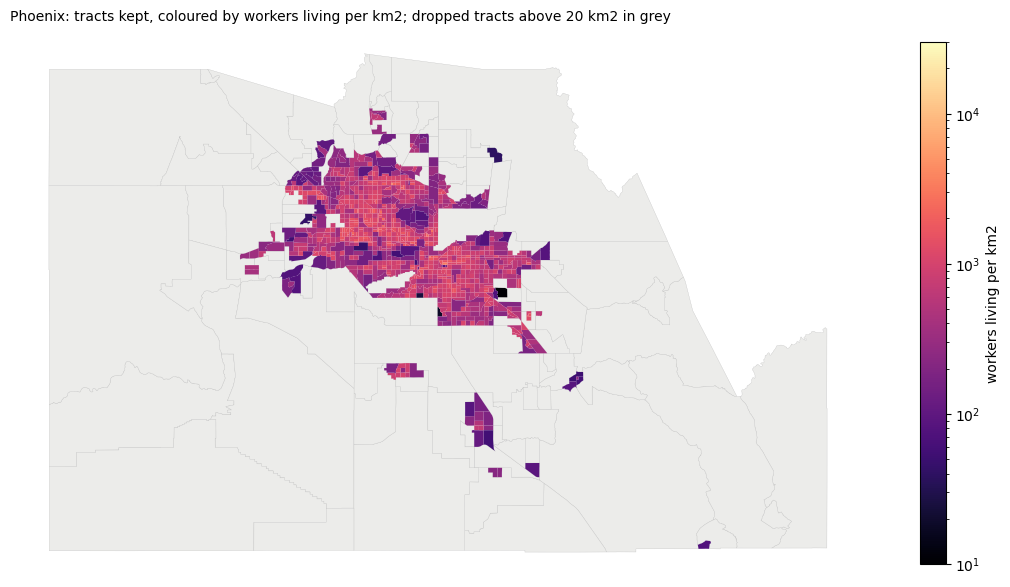

In [14]:
dropped = set(large["tract"])
flows["home_large"] = flows["h_geocode"].str[:11].isin(dropped)
flows["work_large"] = flows["w_geocode"].str[:11].isin(dropped)
flows["dropped"] = flows["home_large"] | flows["work_large"]
workers = flows["S000"].sum()
lost = pd.DataFrame({
    "pairs": [flows["home_large"].sum(), flows["work_large"].sum(), flows["dropped"].sum()],
    "workers": [flows.loc[flows["home_large"], "S000"].sum(), flows.loc[flows["work_large"], "S000"].sum(), flows.loc[flows["dropped"], "S000"].sum()],
}, index=pd.Index(["home in a large tract", "work in a large tract", "either"], name="lost because"))
lost["share of pairs"] = lost["pairs"] / len(flows)
lost["share of workers"] = lost["workers"] / workers
print(f"dropping {len(dropped):,} tracts above {BIG_TRACT_KM2} km2 leaves {len(area_tracts) - len(dropped):,} tracts, "
      f"{(~flows['dropped']).sum():,} block pairs and {flows.loc[~flows['dropped'], 'S000'].sum():,} workers "
      f"({flows.loc[~flows['dropped'], 'S000'].sum() / workers:.1%} of the workers of the area)")
display(lost.round(3))

kept_flows = flows.loc[~flows["dropped"], ["w_geocode", "h_geocode", "S000", "km"]]
print("straight-line distance of the kept flows, weighted by workers (km):")
display(pd.Series(weighted_percentiles(kept_flows["km"].to_numpy(), kept_flows["S000"].to_numpy(), percentiles), index=[f"p{p}" for p in percentiles]).round(1).to_frame("km").T)

kept_tracts = area_tracts.loc[~area_tracts["large"]].drop(columns="large")
kept_tracts.to_parquet(RESULTS / f"tracts-kept-{YEAR}.parquet", index=False)
kept_flows.to_parquet(RESULTS / f"lodes-metro-od-JT01-{YEAR}-kept.parquet", index=False)

figure, axis = plt.subplots(figsize=(11, 9))
area_tracts.loc[area_tracts["large"]].plot(ax=axis, color="#ececea", edgecolor="#bbbbbb", linewidth=0.2)
kept_tracts.plot(column="home_per_km2", ax=axis, cmap="magma", norm=LogNorm(vmin=10, vmax=30000), edgecolor="none",
                 legend=True, legend_kwds={"shrink": 0.6, "label": "workers living per km2"}, missing_kwds={"color": "#ececea"})
axis.set_title(f"{CITY}: tracts kept, coloured by workers living per km2; dropped tracts above {BIG_TRACT_KM2} km2 in grey", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()


## 6. Large blocks

The land-area thresholds of step 4 applied to blocks as well as tracts, so the two units
can be compared: how many units lie above each threshold, how much of the land they cover,
and how many of the area's workers live and work in them. Block land areas come from the
TIGER file of step 2, block workers from step 3.


In [15]:
block_table = area_blocks[["block", "land_km2"]].merge(units["block"], left_on="block", right_index=True)
tract_table = area_tracts[["tract", "land_km2", "workers_home", "workers_work"]]
rows = {}
for unit, table in [("block", block_table), ("tract", tract_table)]:
    for threshold in THRESHOLDS_KM2:
        above = table["land_km2"] > threshold
        rows[(unit, threshold)] = pd.Series({
            "units above": above.sum(),
            "share of units": above.mean(),
            "share of land": table.loc[above, "land_km2"].sum() / table["land_km2"].sum(),
            "share of workers by home": table.loc[above, "workers_home"].sum() / table["workers_home"].sum(),
            "share of workers by work": table.loc[above, "workers_work"].sum() / table["workers_work"].sum(),
            "median land km2 above": table.loc[above, "land_km2"].median(),
            "max land km2": table["land_km2"].max(),
        })
large_units = pd.DataFrame(rows).T
large_units.index.names = ["unit", "threshold km2"]
large_units["units above"] = large_units["units above"].astype(int)
large_units.round(3)


units above  share of units  share of land  \
unit  threshold km2                                               
block 2                     2352           0.032          0.806   
      4                     1207           0.016          0.722   
      10                     558           0.008          0.616   
      20                     281           0.004          0.514   
tract 2                      787           0.713          0.989   
      4                      320           0.290          0.956   
      10                     152           0.138          0.929   
      20                      96           0.087          0.908   

                     share of workers by home  share of workers by work  \
unit  threshold km2                                                       
block 2                                 0.011                     0.030   
      4                                 0.005                     0.006   
      10                                0.002                     0.003   
      20                                0.001                     0.001   
tract 2                                 0.772                     0.798   
      4                                 0.320                     0.380   
      10                                0.153                     0.182   
      20                                0.094                     0.064   

                     median land km2 above  max land km2  
unit  threshold km2                                       
block 2                              4.112       558.857  
      4                              9.167       558.857  
      10                            20.021       558.857  
      20                            39.054       558.857  
tract 2                              3.049      3455.325  
      4                              9.230      3455.325  
      10                            26.813      3455.325  
      20                            66.635      3455.325